In [1]:
pip install requests pandas pymongo

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ----------------- ---------------------- 4.7/10.9 MB 29.9 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 34.5 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 27.7 MB/s  0:00:00
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 831.1/831.1 kB 30.3 MB/s  0:00:00

   ---------------------------------------- 0/3 [dnspython]
   ---------------------------------------- 0/3 [dnspython]
   ---------------------------------------- 0/3 [dnspython]
   ------------- -------------------------- 1/3 [pymongo]
   ------------- -------------------------- 1/3 [pymongo]
   ------------- -------------------------- 1/3 [pymongo]
   ------------- -------------------------- 1/3 [pymongo]
   ------------- -------------------------- 1/3 [pymongo]
   -------------------------- ------------- 2/3 [pandas]
   -----------------


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\paola\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [5]:
import json
import pandas as pd
import requests

# API REST de productos E-Commerce
url_api = "https://dummyjson.com/products?limit=200"

print("Descargando datos desde DummyJSON E-Commerce...")

respuesta = requests.get(url_api)

if respuesta.status_code == 200:
    datos = respuesta.json()
    productos = datos.get("products", [])
    print(f"¡Éxito! Se recolectaron {len(productos)} productos.")

    productos_limpios = []
    for prod in productos:
        item = {
            "id_producto": prod.get("id"),
            "nombre": prod.get("title"),
            "categoria": prod.get("category"),
            "marca": prod.get("brand", "Genérica"),
            "precio_usd": prod.get("price"),
            "descuento_pct": prod.get("discountPercentage"),
            "calificacion": prod.get("rating"),
            "stock": prod.get("stock"),
        }
        productos_limpios.append(item)

    df = pd.DataFrame(productos_limpios)
    print("\n--- Vista previa de productos E-Commerce ---")
    print(df.head())

    # Guardar archivos locales
    with open("muestra_productos.json", "w", encoding="utf-8") as f:
        json.dump(productos_limpios, f, ensure_ascii=False, indent=4)

    df.to_csv("muestra_productos.csv", index=False, encoding="utf-8-sig")
    print(
        "\nArchivos 'muestra_productos.json' y 'muestra_productos.csv'"
        " guardados exitosamente."
    )
else:
    print(f"Error al conectar con la API: {respuesta.status_code}")


Descargando datos desde DummyJSON E-Commerce...
¡Éxito! Se recolectaron 194 productos.

--- Vista previa de productos E-Commerce ---
   id_producto                         nombre categoria           marca  \
0            1  Essence Mascara Lash Princess    beauty         Essence   
1            2  Eyeshadow Palette with Mirror    beauty  Glamour Beauty   
2            3                Powder Canister    beauty    Velvet Touch   
3            4                   Red Lipstick    beauty  Chic Cosmetics   
4            5                Red Nail Polish    beauty    Nail Couture   

   precio_usd  descuento_pct  calificacion  stock  
0        9.99          10.48          2.56     99  
1       19.99          18.19          2.86     34  
2       14.99           9.84          4.64     89  
3       12.99          12.16          4.36     91  
4        8.99          11.44          4.32     79  

Archivos 'muestra_productos.json' y 'muestra_productos.csv' guardados exitosamente.


In [6]:
pip install tinydb matplotlib seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------------ --------------- 5.8/9.5 MB 30.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 29.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 44.7 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 39.1 MB/s  0:00:00

   ---- ----------------------------------- 1/9 [pyparsing]
   -------- ------------------------------- 2/9 [pillow]
   -------- ------------------------------- 2/9 [pillow]
   -------- ------------------------------- 2/9 [pillow]
   ----------------- ---------------------- 4/9 [fonttools]
   ----------------- ---------------------- 4/9 [fonttools]
   ----------------- ---------------------- 4/9 [fonttools]
   ----------------- ---------------------- 4/9 [fonttools]
   ----------------- -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\paola\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [7]:
import json
from tinydb import Query, TinyDB

# 1. Crear la base de datos NoSQL local
db = TinyDB("nosql_productos_db.json")
db.truncate()

# 2. Leer la muestra de datos del paso anterior
with open("muestra_productos.json", "r", encoding="utf-8") as f:
    datos_productos = json.load(f)

# 3. Insertar los documentos en la colección
db.insert_multiple(datos_productos)

print(
    f"¡Éxito! Se insertaron {len(db)} documentos en la Base de Datos NoSQL"
    " TinyDB."
)

¡Éxito! Se insertaron 194 documentos en la Base de Datos NoSQL TinyDB.


In [8]:
Producto = Query()

# --- CONSULTA 1: Filtrado Simple ---
# Requisito: Buscar productos con precio mayor a $50 (o calificación alta)
resultados_filtro = db.search(Producto.precio_usd > 50)
print(f"1. CONSULTA DE FILTRADO: Se encontraron {len(resultados_filtro)} productos con precio > $50 USD.")
print("Ejemplo del primer producto encontrado:", resultados_filtro[0]['nombre'] if resultados_filtro else "Sin resultados")

# --- CONSULTA 2: Agregación ---
# Requisito: Calcular el precio promedio y el stock total de la colección
todos_los_docs = db.all()
precios = [doc['precio_usd'] for doc in todos_los_docs if 'precio_usd' in doc]
stock_total = sum([doc['stock'] for doc in todos_los_docs if 'stock' in doc])
precio_promedio = sum(precios) / len(precios) if precios else 0

print(f"\n2. CONSULTA DE AGREGACIÓN:")
print(f"   - Precio promedio de los productos: ${precio_promedio:.2f} USD")
print(f"   - Stock total acumulado en inventario: {stock_total} unidades")

# --- CONSULTA 3: Consulta según Patrón de Acceso ---
# Definición del patrón: "Búsqueda rápida de productos disponibles con calificación superior a 4.5"
patron_acceso = db.search((Producto.calificacion >= 4.5) & (Producto.stock > 0))
print(f"\n3. CONSULTA POR PATRÓN DE ACCESO: Se encontraron {len(patron_acceso)} productos en stock con alta calificación (>= 4.5).")

1. CONSULTA DE FILTRADO: Se encontraron 77 productos con precio > $50 USD.
Ejemplo del primer producto encontrado: Chanel Coco Noir Eau De

2. CONSULTA DE AGREGACIÓN:
   - Precio promedio de los productos: $1570.10 USD
   - Stock total acumulado en inventario: 9779 unidades

3. CONSULTA POR PATRÓN DE ACCESO: Se encontraron 44 productos en stock con alta calificación (>= 4.5).


C:\Users\paola\AppData\Local\Temp\ipykernel_22380\2034641265.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


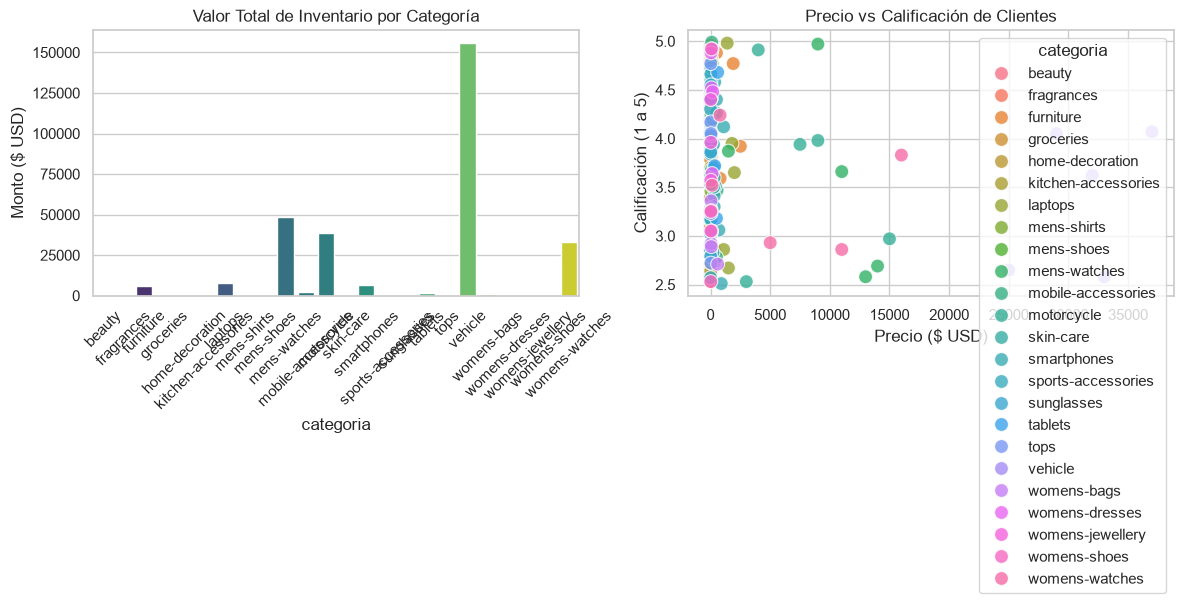

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Cargar los datos desde la BD a un DataFrame para graficar rápido
df = pd.DataFrame(db.all())

# Configurar estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

# Gráfico 1: Distribución de precios por categoría
plt.subplot(1, 2, 1)
sns.barplot(
    data=df,
    x="categoria",
    y="precio_usd",
    estimator=sum,
    errorbar=None,
    palette="viridis",
)
plt.title("Valor Total de Inventario por Categoría")
plt.xticks(rotation=45)
plt.ylabel("Monto ($ USD)")

# Gráfico 2: Relación entre Precio y Calificación
plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df,
    x="precio_usd",
    y="calificacion",
    hue="categoria",
    s=100,
    alpha=0.8,
)
plt.title("Precio vs Calificación de Clientes")
plt.xlabel("Precio ($ USD)")
plt.ylabel("Calificación (1 a 5)")

plt.tight_layout()
plt.show()